# Lesson 6 · Turning results into words: a one-page research note

The earlier lessons produced numbers and figures. This lesson turns them into three things:
1. **a one-page research note** you could send to a potential supervisor or collaborator;
2. **one sentence** that summarises the work, e.g. for an email;
3. **a short spoken explanation** for when someone asks "so what did you do?".

Structure:
- **Part A (code, TODO 1–3)**: compute the "derived numbers" that writing needs, such as fold changes and percentages, from `results/numbers.json`. Readers remember "1.8 times higher"; they do not remember "z = 7.37".
- **Part B (writing, TODO 4–8)**: one sentence per figure panel, then caveats and next steps. Write in the markdown cells (double-click to edit, Shift + Enter to render).
- **Part C (conversation, TODO 9–10)**: a 30-second introduction and answers to the six most likely questions.

The numbers and the figure come from `scripts/make_summary_figure.py`, which repeats the Lesson 5 analysis with a fixed random seed (and 200 instead of 100 shuffles). They are already in `results/`, so you do not need to run it.

## Step 0: load the numbers and the figure (provided)

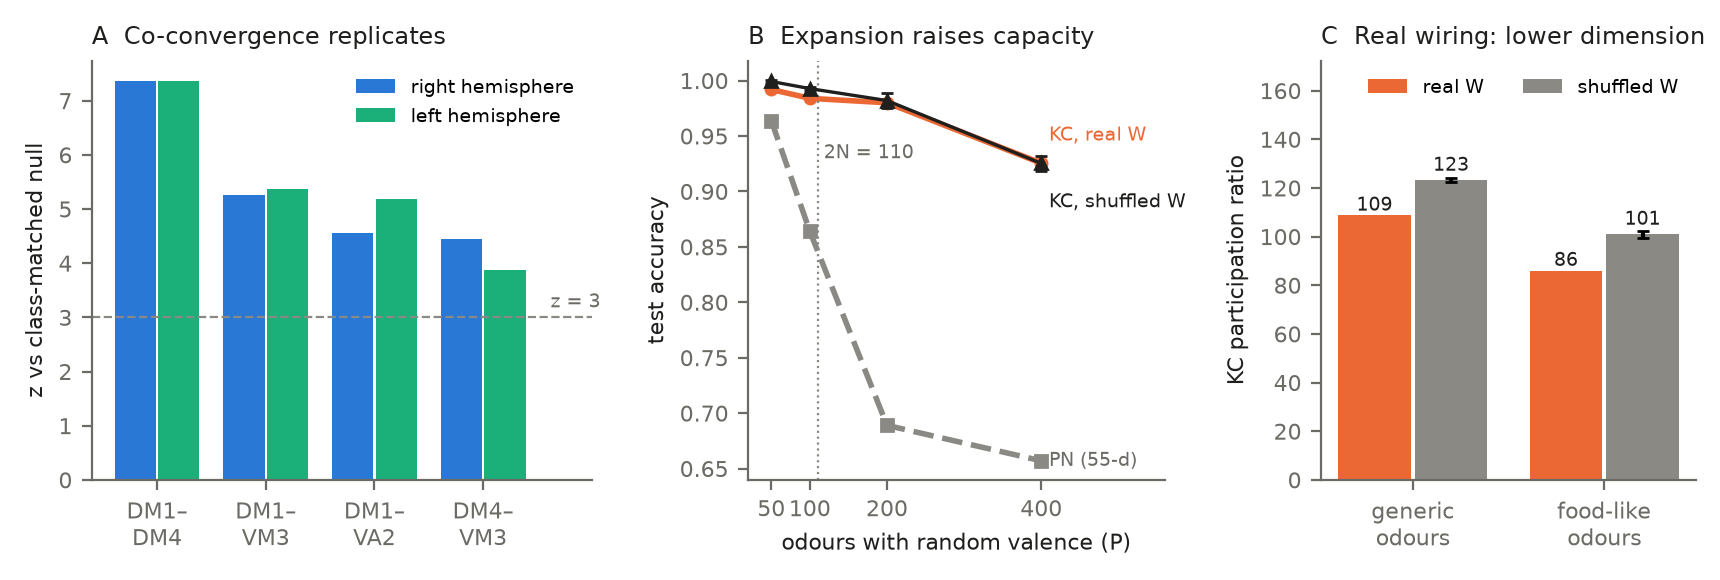

    side     pair  obs  null_mean     z      p
0  right  DM1–DM4   95       52.1  7.37  0.005
1  right  DM1–VM3   54       28.7  5.26  0.005
2  right  DM1–VA2   78       51.7  4.55  0.005
3  right  DM4–VM3   41       22.4  4.45  0.005
4   left  DM1–DM4  102       53.9  7.37  0.005
5   left  DM1–VM3   64       36.1  5.37  0.005
6   left  DM1–VA2   80       48.8  5.19  0.005
7   left  DM4–VM3   43       26.1  3.87  0.005 

   thresh  n_kc  mean_in_degree  z_DM1_DM4
0       1  2390            5.12       6.67
1       3  2373            4.47       7.91
2       5  2334            4.14       7.17
3      10  2155            3.15       4.40 

        PN   real  shuf_mean  shuf_sd
P                                    
50   0.964  0.992      0.999    0.002
100  0.864  0.984      0.993    0.002
200  0.689  0.980      0.982    0.007
400  0.657  0.925      0.925    0.007 

           PN   real  shuf_mean  shuf_sd
generic  51.5  108.7      123.1      0.8
food     50.4   86.0      100.9      1.4


In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

d = json.load(open("../results/numbers.json"))
rep = pd.DataFrame(d["replication"])
sweep = pd.DataFrame(d["threshold_sweep_right"])
cap = pd.DataFrame(d["valence_capacity"]).set_index("P")
dim = pd.DataFrame(d["participation_ratio"]).T
display(Image("../results/summary_figure.png"))
print(rep, "\n"); print(sweep, "\n"); print(cap, "\n"); print(dim)

---
# Part A · Derived numbers

## TODO 1: how many times larger than the null is the observed value?

The z-score tells a reviewer "how unlikely this is under chance"; the **fold change** (`obs / null_mean`) tells a reader "how big the effect is". Report both:
- a large z with a fold change of only 1.05 means a large sample and a small effect;
- a large fold change with a small z means a big effect but not enough data to be sure.

To do: add a column `fold = obs / null_mean` to `rep`, rounded to 2 decimals, and print `side`, `pair`, `obs`, `null_mean`, `fold` and `z`.

In [2]:
# TODO 1
rep["fold"] = (rep.obs / rep.null_mean).round(2)
rep[["side", "pair", "obs", "null_mean", "fold", "z"]]

,side,pair,obs,null_mean,fold,z
0,right,DM1–DM4,95,52.1,1.82,7.37
1,right,DM1–VM3,54,28.7,1.88,5.26
2,right,DM1–VA2,78,51.7,1.51,4.55
3,right,DM4–VM3,41,22.4,1.83,4.45
4,left,DM1–DM4,102,53.9,1.89,7.37
5,left,DM1–VM3,64,36.1,1.77,5.37
6,left,DM1–VA2,80,48.8,1.64,5.19
7,left,DM4–VM3,43,26.1,1.65,3.87


## TODO 2: by what percentage does real wiring reduce dimensionality?

To do: for the `generic` and `food` rows, compute `drop = (shuf_mean - real) / shuf_mean * 100`, store it as `dim["drop_%"]`, round to 1 decimal and print.

Think: the shuffled W values themselves vary (`shuf_sd`). Is the gap convincing? Compute `(shuf_mean - real) / shuf_sd`: this is the z of the comparison.

In [3]:
# TODO 2
dim["drop_%"] = ((dim.shuf_mean - dim.real) / dim.shuf_mean * 100).round(1)
dim["z_vs_shuffled"] = ((dim.shuf_mean - dim.real) / dim.shuf_sd).round(1)
dim

,PN,real,shuf_mean,shuf_sd,drop_%,z_vs_shuffled
generic,51.5,108.7,123.1,0.8,11.7,18.0
food,50.4,86.0,100.9,1.4,14.8,10.6


## TODO 3: how large is the benefit of expansion?

To do:
1. compute by how many **percentage points** the KC code (real W) beats the PN code at P = 400;
2. find the first P at which PN accuracy drops below 0.9.

Hint: `cap.PN < 0.9` is a boolean Series, and `.idxmax()` returns the index of its first True.

Think: compare this P with 2N = 110. This is Cover's theorem again.

In [4]:
# TODO 3
gap = (cap.loc[400, "real"] - cap.loc[400, "PN"]) * 100
first_P = (cap.PN < 0.9).idxmax()
print(f"KC beats PN by {gap:.0f} percentage points at P = 400")
print("PN accuracy first drops below 0.9 at P =", first_P)

KC beats PN by 27 percentage points at P = 400
PN accuracy first drops below 0.9 at P = 100


---
# Part B · Writing

## How strongly to word a claim (hedging in scientific English)

| What evidence you have | Use words like | Example |
|---|---|---|
| significant test + independent replication | *shows*, *is replicated*, *robust to* | Co-convergence of DM1 and DM4 is replicated in the left hemisphere. |
| agrees with the literature, but you have not checked it point by point | *consistent with* | This is consistent with structured sampling reported by Zheng et al. (2022). |
| holds only in a toy model | *in this model*, *suggests*, *may* | In this toy model, structured wiring does not improve learning capacity. |
| speculation or an open question | *raises the question*, *one possibility is* | One possibility is that the dimensionality cost buys sensitivity to food odours. |

**Three common mistakes:**
1. **Overclaiming:** "I discovered that the fly brain is optimised for food." It is not a discovery, and there is no evidence for "optimised".
2. **Jumping from model to biology:** "Real flies learn food odours worse." The model is not a fly.
3. **A number with nothing to compare against:** "z = 7.4." Say relative to which null: "7.4 SD above a class-matched, degree-preserving null".

## TODO 4: one-sentence conclusion for Panel A

Requirements:
- include the fold change and z;
- say what the null is, and that the result replicates in the left hemisphere;
- mention robustness to the threshold;
- 1–2 sentences, in English.

**TODO 4 (example answer):**

DM1 and DM4 share 1.8 times more KCs than expected under a degree-preserving null shuffled within KC class (z = 7.4 in the right hemisphere), and this was replicated as a pre-specified test in the left hemisphere (z = 7.4); all four strongest pairs replicate (z = 3.9–7.4), and DM1–DM4 stays significant at every synapse threshold from 1 to 10 (z = 4.4–7.9).

## TODO 5: one-sentence conclusion for Panel B

Requirements:
- make clear the task is random valence learning (half a sentence on why this task);
- use the numbers from TODO 3;
- restrict the claim to the toy model.

**TODO 5 (example answer):**

In a toy model of random valence learning, the task in which the capacity limit of a linear readout matters, a linear readout of the 55 glomerular channels degrades as the number of odours approaches 2N ≈ 110 (0.86 at P = 100, 0.66 at P = 400), whereas the expanded, sparsified KC code still reaches 0.93 at P = 400, 27 percentage points higher.

## TODO 6: one-sentence conclusion for Panel C, the "turning point" of the note

Requirements:
- first say that capacity is the same, then that dimensionality is lower (use the percentage from TODO 2), and that this also holds for food-like odours;
- join the two with a contrast word such as *but*, *yet* or *however*.

**TODO 6 (example answer):**

Real and shuffled wiring support the same learning capacity (both 0.93 at P = 400), yet the real wiring gives a KC representation with about 12% lower participation ratio for generic odours and 15% lower for food-like odours, so the structure has a dimensionality cost without a visible benefit in this setting.

## TODO 7: caveats (3–4, one sentence each)

A good caveat has two features:
- it says **how it could change the conclusion**, not just that "there are limitations";
- ideally, it says **how to fix it**.

Example:
- weak: "The model is simple."
- good: "Odours were synthetic, so the absence of a benefit for food-like odours says nothing yet about real odour statistics; DoOR response data would address this."

**TODO 7 (example answer):**

- Odours were synthetic, so the absence of a benefit for food-like odours says nothing yet about real odour statistics; measured glomerular responses (DoOR) would address this.
- The readout was a single logistic-regression MBON with a fixed 5% sparsity, so a benefit of structure could appear with other readouts, sparsity levels or learning rules; sweeping these would test that.
- Only uniglomerular PNs and calyx synapses were included, so inputs from multiglomerular PNs, which might change the effective wiring, were ignored.
- The model analysis used the right hemisphere only; repeating it on the left would show whether the dimensionality cost replicates like the co-convergence does.

## TODO 8: the Question and "What I would do next"

This is the most important part of the note, and the part the reader will remember.

Structure:
- **Question**: 1–2 sentences. Start from your motivation and arrive at a concrete question;
- **Next**: 2–3 items, each a concrete analysis. If you are writing to a specific lab, connect at least one item to their work (for example, a new connectome data set they produced, or a modelling method they use).

**TODO 8 (example answer):**

**Question:** How does wiring constrain computation? In the mushroom body, PN→KC wiring is structured rather than random, but in a simple model this structure costs representational dimension without improving learning, so what is it for?

**Next:**
- Replace synthetic odours with measured glomerular responses (DoOR) and ask whether real wiring helps for real food odours specifically.
- Vary the readout (sparsity, learning rule, multiple MBONs) to see whether any setting turns the dimensionality cost into a benefit.
- Repeat the co-convergence and dimensionality analyses in another connectome (e.g. a second fly) to test whether the structure is conserved across individuals.

---
# Part C · Preparing for a conversation

When you talk to a potential supervisor, they usually do not test you on details. They look for three things:
1. whether you really understand what you did;
2. whether you know its limitations;
3. whether you are interested in **their** questions.

## TODO 9: a 30-second introduction (say it out loud three times, with a timer)

Structure: who you are (1 sentence) → what you did and what you saw (2 sentences) → what it makes you want to ask, and how it connects to their work (1 sentence).

Write it down, but **do not memorise a script**; remember the four points.

**TODO 9 (example answer):**

I'm a student interested in how wiring shapes computation. To learn the FlyWire data, I tested whether PN→KC wiring in the mushroom body is random and found that DM1 and DM4 share almost twice as many KCs as a degree-preserving null predicts, replicated in the other hemisphere. In a simple learning model this structure lowered the dimensionality of the KC code without improving learning, which made me wonder whether it is tuned to real food-odour statistics, and that is something I would like to test with your data.

## TODO 10: the six most likely questions

Answer each in 2–3 English sentences. If you get stuck, go back to the lesson in brackets.
1. *Why did you shuffle within KC class?* (Lesson 4)
2. *Why 5 synapses? What happens at other thresholds?* (Lessons 3 and 5)
3. *Why does expansion help? Why do you need the sparsening step?* (Lesson 5, Part B)
4. *Why do you think real wiring has lower dimensionality?* (Lesson 5, Part D)

   Hint: DM1, DM4 and the others are shared by many KCs, so KC inputs are correlated and the representation is squeezed into fewer directions.
5. *What would you do in eight weeks here?* (TODO 8; connect it to their lab's work)
6. *Tell me about an earlier project where you had to check whether a result held up.*

   Prepare a concrete example from your own experience, and say what it has in common with this analysis: in both, the question is whether a conclusion survives a fair control.

**TODO 10 (example answers for 1–4; 5 and 6 depend on you):**

1. The three KC classes prefer different glomeruli. Shuffling all KCs together would count that class preference as pair structure, so shuffling within class asks whether DM1 and DM4 co-occur more than expected *given* class preferences; it lowered z from about 9.5 to about 7, but it stayed highly significant.
2. Edges with fewer than 5 synapses are many but carry few synapses, and they are the most likely to be detection errors. The co-convergence result holds at every threshold from 1 to 10 (z = 4.4–7.9); only the inputs-per-KC number changes (5.1 to 3.2).
3. A linear readout of N channels can only learn about 2N arbitrary associations (Cover's theorem). Expanding to ~2,000 KCs raises that limit, but only if the expansion is nonlinear: without the sparsening step the KC code would still lie in the 55-dimensional PN subspace.
4. When many KCs share the same pairs of glomeruli, their inputs are correlated, so their responses vary together and the variance is concentrated in fewer directions. Random wiring spreads inputs more evenly and decorrelates the KCs.

## When you are done

1. Combine TODO 4–8 into one page (about 400 words plus the figure): Title, Question, Data & methods, Observations (A, B, C), Caveats, What I would do next.
2. Check every number in the note against `results/numbers.json`, and check every sentence against the hedging table for overclaiming.
3. Take one sentence from TODO 4 as the summary line for an email.